In [31]:
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict

pd.set_option("display.max_columns", 200)

In [32]:
# load your Olympic data (same as your other notebooks)
athletes = pd.read_csv("athlete_events.csv")
nocs = pd.read_csv("noc_regions.csv")

df = athletes.merge(nocs, on="NOC", how="left").rename(columns={"region": "Country"})
df = df[df["Season"] == "Summer"].copy()
df["Medal_Won"] = df["Medal"].notna().astype(int)

# We'll start with Rio 2016 medals for a clean same-year comparison
rio = df[df["Year"] == 2016].copy()

country_medals_2016 = (
    rio[rio["Medal_Won"] == 1]
    .groupby("Country")["Medal_Won"]
    .sum()
    .reset_index(name="Actual_Medals_2016")
)

country_medals_2016.head(15)

,Country,Actual_Medals_2016
0,Algeria,2
1,Argentina,22
2,Armenia,4
3,Australia,82
4,Austria,2
5,Azerbaijan,18
6,Bahamas,6
7,Bahrain,2
8,Belarus,12
9,Belgium,21


In [33]:
import io
import zipfile
import requests
import pandas as pd
import numpy as np

def fetch_wb_indicator_bulk(indicator_code, year="2016"):
    # More reliable than the paged JSON endpoint
    url = f"https://api.worldbank.org/v2/en/indicator/{indicator_code}?downloadformat=csv"
    r = requests.get(url, timeout=(20, 120))  # connect timeout, read timeout
    r.raise_for_status()

    z = zipfile.ZipFile(io.BytesIO(r.content))
    data_files = [
        n for n in z.namelist()
        if n.startswith("API_") and n.endswith(".csv") and "Metadata" not in n
    ]
    if not data_files:
        raise ValueError(f"No data CSV found in zip for {indicator_code}")

    df = pd.read_csv(z.open(data_files[0]), skiprows=4)

    out = df[["Country Name", "Country Code", year]].copy()
    out.columns = ["Country_WB", "ISO3_WB", indicator_code]
    return out

wb_gdp = fetch_wb_indicator_bulk("NY.GDP.PCAP.CD", year="2016")
wb_pop = fetch_wb_indicator_bulk("SP.POP.TOTL", year="2016")
# optional:
# wb_edu = fetch_wb_indicator_bulk("SE.XPD.TOTL.GD.ZS", year="2016")

wb = wb_gdp.merge(wb_pop, on=["Country_WB", "ISO3_WB"], how="outer")
wb.head()

,Country_WB,ISO3_WB,NY.GDP.PCAP.CD,SP.POP.TOTL
0,Afghanistan,AFG,522.082216,34700612.0
1,Africa Eastern and Southern,AFE,1334.470500,623369401.0
2,Africa Western and Central,AFW,1630.039439,429454743.0
3,Albania,ALB,4457.634122,2689469.0
4,Algeria,DZA,4424.985290,40850721.0


In [34]:
print(wb.shape)
print(wb[["NY.GDP.PCAP.CD", "SP.POP.TOTL"]].isna().sum())

(266, 4)
NY.GDP.PCAP.CD    7
SP.POP.TOTL       1
dtype: int64


In [35]:
# Cell 5: Keep only country rows from World Bank (remove aggregates/regions)
wb_clean = wb.copy()

# keep valid ISO3 rows
wb_clean = wb_clean[wb_clean["ISO3_WB"].notna()]
wb_clean = wb_clean[wb_clean["ISO3_WB"].str.len() == 3]

# remove common aggregate entities
agg_keywords = [
    "income", "IDA", "IBRD", "World", "Euro area", "European Union",
    "OECD", "Arab World", "Sub-Saharan", "Latin America", "Caribbean",
    "Middle East", "North America", "South Asia", "East Asia", "Pacific",
    "Africa", "small states", "Fragile", "Heavily indebted", "countries"
]
mask_agg = wb_clean["Country_WB"].str.contains("|".join(agg_keywords), case=False, na=False)
wb_clean = wb_clean[~mask_agg].copy()

print(wb_clean.shape)
print(wb_clean[["NY.GDP.PCAP.CD", "SP.POP.TOTL"]].isna().sum())
wb_clean.head()

(221, 4)
NY.GDP.PCAP.CD    7
SP.POP.TOTL       1
dtype: int64


,Country_WB,ISO3_WB,NY.GDP.PCAP.CD,SP.POP.TOTL
0,Afghanistan,AFG,522.082216,34700612.0
3,Albania,ALB,4457.634122,2689469.0
4,Algeria,DZA,4424.985290,40850721.0
5,American Samoa,ASM,12843.334290,52245.0
6,Andorra,AND,40129.838581,72181.0


In [36]:
# Cell 6 (REPLACE): Build 2016 medal counts INCLUDING zero-medal countries
rio = df[df["Year"] == 2016].copy()
rio = rio[rio["Country"].notna()].copy()

# All participating countries in Rio 2016
participants_2016 = (
    rio[["Country"]]
    .drop_duplicates()
    .copy()
)

# Medal awards (event-level dedupe to avoid team-row inflation)
rio_medals = rio[rio["Medal"].notna()].copy()
event_cols = ["Games", "Year", "Season", "City", "Sport", "Event", "NOC", "Medal"]
rio_event_medals = rio_medals.drop_duplicates(event_cols).copy()

medals_2016 = (
    rio_event_medals.groupby("Country")
    .size()
    .reset_index(name="Actual_Medals_2016")
)

# Left join so non-medal countries are kept with 0
country_medals_2016 = (
    participants_2016
    .merge(medals_2016, on="Country", how="left")
    .fillna({"Actual_Medals_2016": 0})
)

country_medals_2016["Actual_Medals_2016"] = country_medals_2016["Actual_Medals_2016"].astype(int)

print("Participating countries:", len(country_medals_2016))
print("Countries with zero medals:", (country_medals_2016["Actual_Medals_2016"] == 0).sum())
country_medals_2016.sort_values("Actual_Medals_2016", ascending=False).head(12)

Participating countries: 203
Countries with zero medals: 118


,Country,Actual_Medals_2016
10,USA,121
72,China,70
50,UK,67
19,Russia,56
21,Germany,42
4,France,42
48,Japan,41
29,Australia,29
2,Italy,28
20,Canada,22


In [37]:
# Cell 7: Harmonize country names and merge medals with World Bank data
name_map = {
    "USA": "United States",
    "UK": "United Kingdom",
    "Russia": "Russian Federation",
    "South Korea": "Korea, Rep.",
    "North Korea": "Korea, Dem. People's Rep.",
    "Iran": "Iran, Islamic Rep.",
    "Egypt": "Egypt, Arab Rep.",
    "Venezuela": "Venezuela, RB",
    "Czech Republic": "Czechia",
    "Slovakia": "Slovak Republic",
    "Bahamas": "Bahamas, The",
    "Gambia": "Gambia, The",
    "Laos": "Lao PDR",
    "Vietnam": "Viet Nam",
    "Syria": "Syrian Arab Republic",
    "Ivory Coast": "Cote d'Ivoire",
    "Boliva": "Bolivia",
    "Brunei": "Brunei Darussalam",
    "Republic of Congo": "Congo, Rep.",
    "Democratic Republic of the Congo": "Congo, Dem. Rep.",
    "Cape Verde": "Cabo Verde",
    "Kyrgyzstan": "Kyrgyz Republic",
    "Macedonia": "North Macedonia",
    "Micronesia": "Micronesia, Fed. Sts."
}

country_medals_2016["Country_for_join"] = country_medals_2016["Country"].replace(name_map)

model_df = country_medals_2016.merge(
    wb_clean,
    left_on="Country_for_join",
    right_on="Country_WB",
    how="left"
)

print("Total medal-winning countries:", len(model_df))
print("Missing GDP:", model_df["NY.GDP.PCAP.CD"].isna().sum())
print("Missing Population:", model_df["SP.POP.TOTL"].isna().sum())

# inspect unmatched
model_df[model_df["NY.GDP.PCAP.CD"].isna()][["Country", "Country_for_join"]].head(20)

Total medal-winning countries: 203
Missing GDP: 21
Missing Population: 18


,Country,Country_for_join
39,Palestine,Palestine
49,Saint Kitts,Saint Kitts
52,Turkey,Turkey
53,Eritrea,Eritrea
59,Puerto Rico,Puerto Rico
63,South Africa,South Africa
71,Trinidad,Trinidad
77,Individual Olympic Athletes,Individual Olympic Athletes
85,Saint Vincent,Saint Vincent
121,Saint Lucia,Saint Lucia


In [38]:
# Cell 8 (REPLACE): Prepare modeling dataset
m = model_df.copy()

m = m.dropna(subset=["NY.GDP.PCAP.CD", "SP.POP.TOTL", "Actual_Medals_2016"]).copy()
m = m[(m["NY.GDP.PCAP.CD"] > 0) & (m["SP.POP.TOTL"] > 0)].copy()

m["log_gdp_pc"] = np.log(m["NY.GDP.PCAP.CD"])
m["log_pop"] = np.log(m["SP.POP.TOTL"])

X = m[["log_pop", "log_gdp_pc"]].copy()
y = m["Actual_Medals_2016"].copy()

print("Model rows:", len(m))
print("Zero-medal rows in model:", (y == 0).sum())
m.head()

Model rows: 182
Zero-medal rows in model: 104


,Country,Actual_Medals_2016,Country_for_join,Country_WB,ISO3_WB,NY.GDP.PCAP.CD,SP.POP.TOTL,log_gdp_pc,log_pop
0,Romania,4,Romania,Romania,ROU,9404.540059,19702267.0,9.148948,16.796244
1,Spain,17,Spain,Spain,ESP,26755.606115,46458139.0,10.194499,17.654062
2,Italy,28,Italy,Italy,ITA,31391.569290,60115223.0,10.354295,17.911774
3,Azerbaijan,18,Azerbaijan,Azerbaijan,AZE,3880.685228,9757812.0,8.263767,16.093579
4,France,42,France,France,FRA,37024.215713,66724104.0,10.519327,18.016077


In [39]:
# Cell 9 (REPLACE): Fit count model + out-of-fold expected medals
from sklearn.linear_model import PoissonRegressor
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error

# Count model is better for medal counts than plain linear regression
model = PoissonRegressor(alpha=0.1, max_iter=2000)

n_splits = min(5, len(m))
kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

# Out-of-fold expected medals (no leakage)
m["Expected_Medals_OOF"] = cross_val_predict(model, X, y, cv=kf, method="predict")
m["Expected_Medals_OOF"] = np.maximum(m["Expected_Medals_OOF"], 0)

# Fit full model for reporting coefficients
model.fit(X, y)
m["Expected_Medals_FullFit"] = np.maximum(model.predict(X), 0)

# Resource-adjusted index
m["RAPI"] = m["Actual_Medals_2016"] - m["Expected_Medals_OOF"]

print("OOF R^2:", round(r2_score(y, m["Expected_Medals_OOF"]), 3))
print("OOF MAE:", round(mean_absolute_error(y, m["Expected_Medals_OOF"]), 3))
print("Poisson coefficients:", dict(zip(["log_pop", "log_gdp_pc"], model.coef_)))

OOF R^2: 0.802
OOF MAE: 3.129
Poisson coefficients: {'log_pop': np.float64(0.6500269444382231), 'log_gdp_pc': np.float64(0.7848562542742868)}


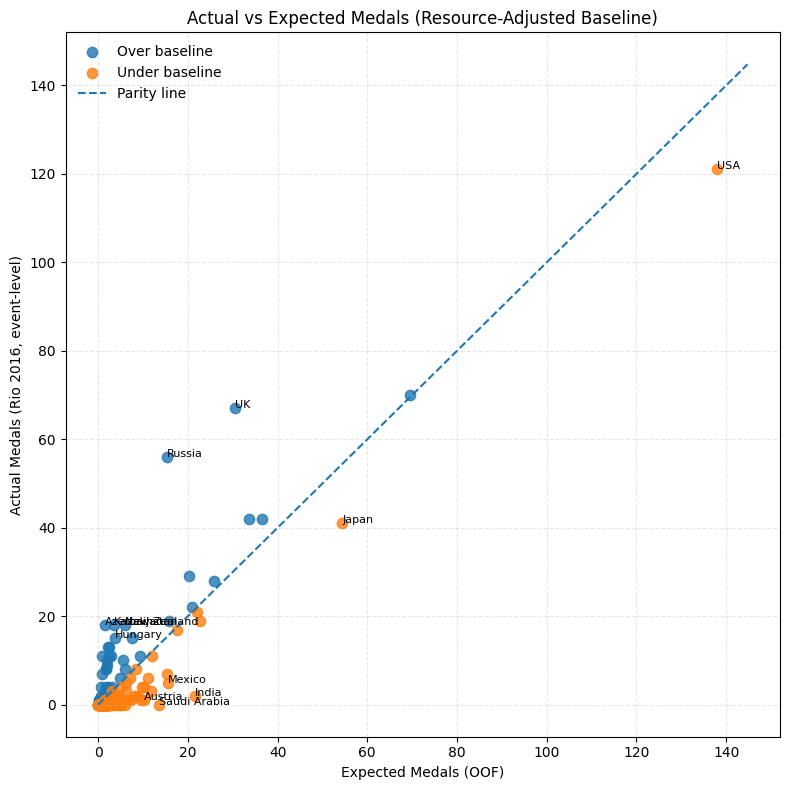

In [40]:
# Cell 10 (REPLACE, optional): clearer over/under coloring
plt.figure(figsize=(8, 8))

over_mask = m["RAPI"] >= 0
under_mask = ~over_mask

plt.scatter(
    m.loc[over_mask, "Expected_Medals_OOF"],
    m.loc[over_mask, "Actual_Medals_2016"],
    alpha=0.8, s=55, label="Over baseline"
)
plt.scatter(
    m.loc[under_mask, "Expected_Medals_OOF"],
    m.loc[under_mask, "Actual_Medals_2016"],
    alpha=0.8, s=55, label="Under baseline"
)

max_val = max(m["Expected_Medals_OOF"].max(), m["Actual_Medals_2016"].max()) * 1.05
plt.plot([0, max_val], [0, max_val], linestyle="--", linewidth=1.5, label="Parity line")

to_label = pd.concat([m.nlargest(6, "RAPI"), m.nsmallest(6, "RAPI")]).drop_duplicates("Country")
for _, r in to_label.iterrows():
    plt.annotate(r["Country"], (r["Expected_Medals_OOF"], r["Actual_Medals_2016"]), fontsize=8)

plt.title("Actual vs Expected Medals (Resource-Adjusted Baseline)")
plt.xlabel("Expected Medals (OOF)")
plt.ylabel("Actual Medals (Rio 2016, event-level)")
plt.grid(alpha=0.3, linestyle="--")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

In [41]:
# Cell 11: Top overperformers / underperformers tables
over = m.sort_values("RAPI", ascending=False)[
    ["Country", "Actual_Medals_2016", "Expected_Medals_OOF", "RAPI", "NY.GDP.PCAP.CD", "SP.POP.TOTL"]
].head(12)

under = m.sort_values("RAPI", ascending=True)[
    ["Country", "Actual_Medals_2016", "Expected_Medals_OOF", "RAPI", "NY.GDP.PCAP.CD", "SP.POP.TOTL"]
].head(12)

print("Top Overperformers:")
display(over)

print("Top Underperformers:")
display(under)

Top Overperformers:


,Country,Actual_Medals_2016,Expected_Medals_OOF,RAPI,NY.GDP.PCAP.CD,SP.POP.TOTL
19,Russia,56,15.263350,40.736650,8663.158203,145015460.0
50,UK,67,30.415813,36.584187,41257.908555,65607000.0
3,Azerbaijan,18,1.494719,16.505281,3880.685228,9757812.0
15,Kazakhstan,18,3.615683,14.384317,7475.566887,18363600.0
51,New Zealand,18,6.034907,11.965093,40113.719538,4714100.0
112,Hungary,15,3.695338,11.304662,13215.860528,9759755.0
26,Kenya,13,2.145016,10.854984,1554.126103,48139687.0
17,Uzbekistan,13,2.423325,10.576675,2753.379514,31284568.0
97,Jamaica,11,0.821517,10.178483,5302.295534,2809915.0
29,Australia,29,20.305864,8.694136,50084.444061,24190907.0


Top Underperformers:


,Country,Actual_Medals_2016,Expected_Medals_OOF,RAPI,NY.GDP.PCAP.CD,SP.POP.TOTL
41,India,2,21.646119,-19.646119,1707.508929,1.343944e+09
10,USA,121,137.860262,-16.860262,57638.101837,3.243533e+08
40,Saudi Arabia,0,13.462228,-13.462228,22267.721705,3.095420e+07
48,Japan,41,54.434358,-13.434358,39375.473162,1.270760e+08
22,Mexico,5,15.595942,-10.595942,9097.923977,1.222514e+08
86,Austria,1,10.134153,-9.134153,45061.499392,8.736668e+06
68,Indonesia,3,11.831893,-8.831893,3521.469435,2.646274e+08
80,United Arab Emirates,1,9.620047,-8.620047,42721.099938,8.935095e+06
31,Switzerland,7,15.355032,-8.355032,82153.074545,8.373338e+06
9,Ireland,2,8.794664,-6.794664,64129.557154,4.762722e+06


In [42]:
# Cell 12 (optional but great): Peer benchmark suggestions for underperformers
# Find overperforming peers with similar resource profile
from sklearn.metrics.pairwise import euclidean_distances

peer_df = m[["Country", "log_pop", "log_gdp_pc", "RAPI", "Actual_Medals_2016"]].copy()

under_candidates = peer_df[peer_df["RAPI"] < 0].copy()
over_candidates = peer_df[peer_df["RAPI"] > 0].copy()

rows = []
for _, u in under_candidates.iterrows():
    if len(over_candidates) == 0:
        break
    d = euclidean_distances(
        [[u["log_pop"], u["log_gdp_pc"]]],
        over_candidates[["log_pop", "log_gdp_pc"]].values
    ).flatten()
    best_idx = d.argmin()
    peer = over_candidates.iloc[best_idx]
    rows.append({
        "Underperforming_Country": u["Country"],
        "Suggested_Peer": peer["Country"],
        "Under_RAPI": u["RAPI"],
        "Peer_RAPI": peer["RAPI"],
        "Resource_Distance": d[best_idx]
    })

peer_recs = pd.DataFrame(rows).sort_values("Resource_Distance").head(15)
peer_recs

,Underperforming_Country,Suggested_Peer,Under_RAPI,Peer_RAPI,Resource_Distance
20,Jordan,Azerbaijan,-0.620382,16.505281,0.036869
74,Libya,Bulgaria,-1.896777,0.844042,0.054739
18,Portugal,Czech Republic,-4.753903,4.371868,0.067408
82,Lebanon,Bulgaria,-1.951241,0.844042,0.092732
28,Turkmenistan,Serbia,-1.595102,6.224794,0.115828
77,Togo,Tajikistan,-0.384462,0.636541,0.122370
23,Ghana,Ivory Coast,-1.831634,0.337610,0.124667
37,Paraguay,Serbia,-1.537528,6.224794,0.126766
67,Dominican Republic,Cuba,-1.463949,8.171994,0.140760
72,Cyprus,Bahrain,-1.718653,0.146904,0.141910
